# Task 3: Trò Chơi Kakuro — Thực Nghiệm Bài Toán Thỏa Mãn Ràng Buộc (CSP)
Đánh giá bộ giải OOP hiện tại trên 4 bảng JSON, 3 cấu hình: Baseline Backtracking; BT + Forward Checking + MRV (có Sum Partitions); BT + Extended AC-3 + MRV/Degree/LCV (có Sum Partitions và FC). Kiểm chứng AllDifferent, Exact Sum, miền 1–9 và givens. Các phép đo không bật UI/trace. Bảng 5x5 và 9x9 lấy từ source hiện tại, chưa đối chiếu độc lập với đề gốc.

In [1]:
import sys, platform, random, tempfile
from pathlib import Path
from threading import Event
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

cwd = Path.cwd().resolve()
TASK_DIR = next((p for p in (cwd, cwd / 'task3', cwd / 'source' / 'task3')
                 if (p / 'csp_model.py').is_file() and (p / 'maps').is_dir()), None)
if TASK_DIR is None:
    raise FileNotFoundError('Run from task3, source, or the project root.')
sys.path.insert(0, str(TASK_DIR.parent))
from task3 import KakuroCSP, KakuroSolver, SolverMode, SumPartitionCatalog
from task3.board_editor import BoardEditor
MAPS_DIR = TASK_DIR / 'maps'
FIG_DIR = TASK_DIR / 'figures'
FIG_DIR.mkdir(exist_ok=True)
plt.rcParams['figure.dpi'] = 130
print(f'Python {platform.python_version()} | {platform.system()} {platform.release()} | {platform.machine()}')
print(f'NumPy {np.__version__} | pandas {pd.__version__}')
print('Task 3 environment ready.')

Python 3.13.5 | Linux 6.18.57 | x86_64
NumPy 2.3.5 | pandas 2.2.3
Task 3 environment ready.


## 1. Đánh Giá Tính Đúng Đắn, Độ Ổn Định Và Hiệu Năng Trên Các Bảng Kakuro
Mỗi cặp bảng/cấu hình chạy làm nóng một lần (không tính), sau đó đo 30 lần với solver mới, cùng giới hạn 300.000 lượt thử ứng viên. Dùng thời gian nội bộ của solver (`perf_counter`, không bao gồm xác minh cuối và không ghi trace). Cache Sum Partitions được làm nóng trước. Độ lệch chuẩn mẫu (ddof=1) thể hiện độ biến động thời gian; không khẳng định độ ổn định trên các bảng chưa thử. Nodes là số ứng viên được thử, kể cả từ chối; Backtracks là số lần hủy phép gán. Pruned Values là lượt loại ứng viên trong tiền xử lý/lan truyền thật, không tính thử LCV. Tỷ lệ thành công dựa trên nghiệm được xác minh độc lập qua `verify_solution`.

In [2]:
board_files = {
    '5x5': 'board_5x5_example.json', '6x6': 'board_6x6_medium.json',
    '8x8': 'board_8x8_hard.json', '9x9': 'board_9x9_complex.json',
}
modes = [SolverMode.PLAIN_BT, SolverMode.BT_FC, SolverMode.BT_MAC_HEURISTICS]
short_names = dict(zip(modes, ['Basic BT', 'FC + MRV', 'Advanced']))
TRIALS, NODE_LIMIT = 30, 300_000
SumPartitionCatalog.initialize()
boards = {label: KakuroCSP.from_json(MAPS_DIR / name) for label, name in board_files.items()}
board_info = pd.DataFrame([{'Board': label, 'Variables |X|': len(csp.variables), 'Runs': len(csp.runs)}
                           for label, csp in boards.items()])
display(board_info)
records = []
solved_9x9 = None
for label, csp in boards.items():
    for mode in modes:
        KakuroSolver(mode=mode, record_steps=False, node_limit=NODE_LIMIT).solve(csp)
    # Rotate execution order per repeat to reduce systematic ordering effects.
    for trial in range(TRIALS):
        for mode in modes[trial % len(modes):] + modes[:trial % len(modes)]:
            res = KakuroSolver(mode=mode, record_steps=False, node_limit=NODE_LIMIT).solve(csp)
            verified = res.solved and res.valid_verified and csp.verify_solution(res.assignment)
            records.append({'Board': label, 'Mode': short_names[mode], 'Trial': trial + 1,
                            'Nodes': res.nodes_explored, 'Backtracks': res.backtracks,
                            'Pruned': res.pruned_values, 'Time (ms)': res.elapsed_ms,
                            'Status': res.status, 'Verified': verified})
            if label == '9x9' and mode == SolverMode.BT_MAC_HEURISTICS and verified:
                solved_9x9 = dict(res.assignment)
df_trials = pd.DataFrame(records)
order = pd.MultiIndex.from_product([list(boards), list(short_names.values())], names=['Board', 'Mode'])
df_csp = (df_trials.groupby(['Board', 'Mode']).agg(
    Trials=('Trial','count'), Nodes_mean=('Nodes','mean'), Backtracks_mean=('Backtracks','mean'),
    Pruned_mean=('Pruned','mean'), Time_mean_ms=('Time (ms)','mean'),
    Time_std_ms=('Time (ms)','std'), Success_pct=('Verified',lambda x: 100*x.mean()))
    .reindex(order))
display(df_csp.round(3))
print(f'Verified: {df_trials.Verified.sum()}/{len(df_trials)}')
print(df_trials.Status.value_counts().to_string())
assert len(df_trials) == 4 * 3 * TRIALS
assert df_trials.Verified.all(), 'At least one preset run failed verification.' 

,Board,Variables |X|,Runs
0,5x5,12,8
1,6x6,19,12
2,8x8,41,22
3,9x9,48,28


Trials  Nodes_mean  ...  Time_std_ms  Success_pct
Board Mode                          ...                          
5x5   Basic BT      30      9933.0  ...        0.989        100.0
      FC + MRV      30        13.0  ...        0.057        100.0
      Advanced      30        12.0  ...        0.199        100.0
6x6   Basic BT      30      6145.0  ...        1.471        100.0
      FC + MRV      30        19.0  ...        0.527        100.0
      Advanced      30        19.0  ...        6.920        100.0
8x8   Basic BT      30      8645.0  ...        1.118        100.0
      FC + MRV      30        63.0  ...        0.228        100.0
      Advanced      30        41.0  ...        2.663        100.0
9x9   Basic BT      30      9141.0  ...        1.093        100.0
      FC + MRV      30       100.0  ...       17.431        100.0
      Advanced      30        48.0  ...        1.765        100.0

[12 rows x 7 columns]

Verified: 360/360
Status
SOLVED    360


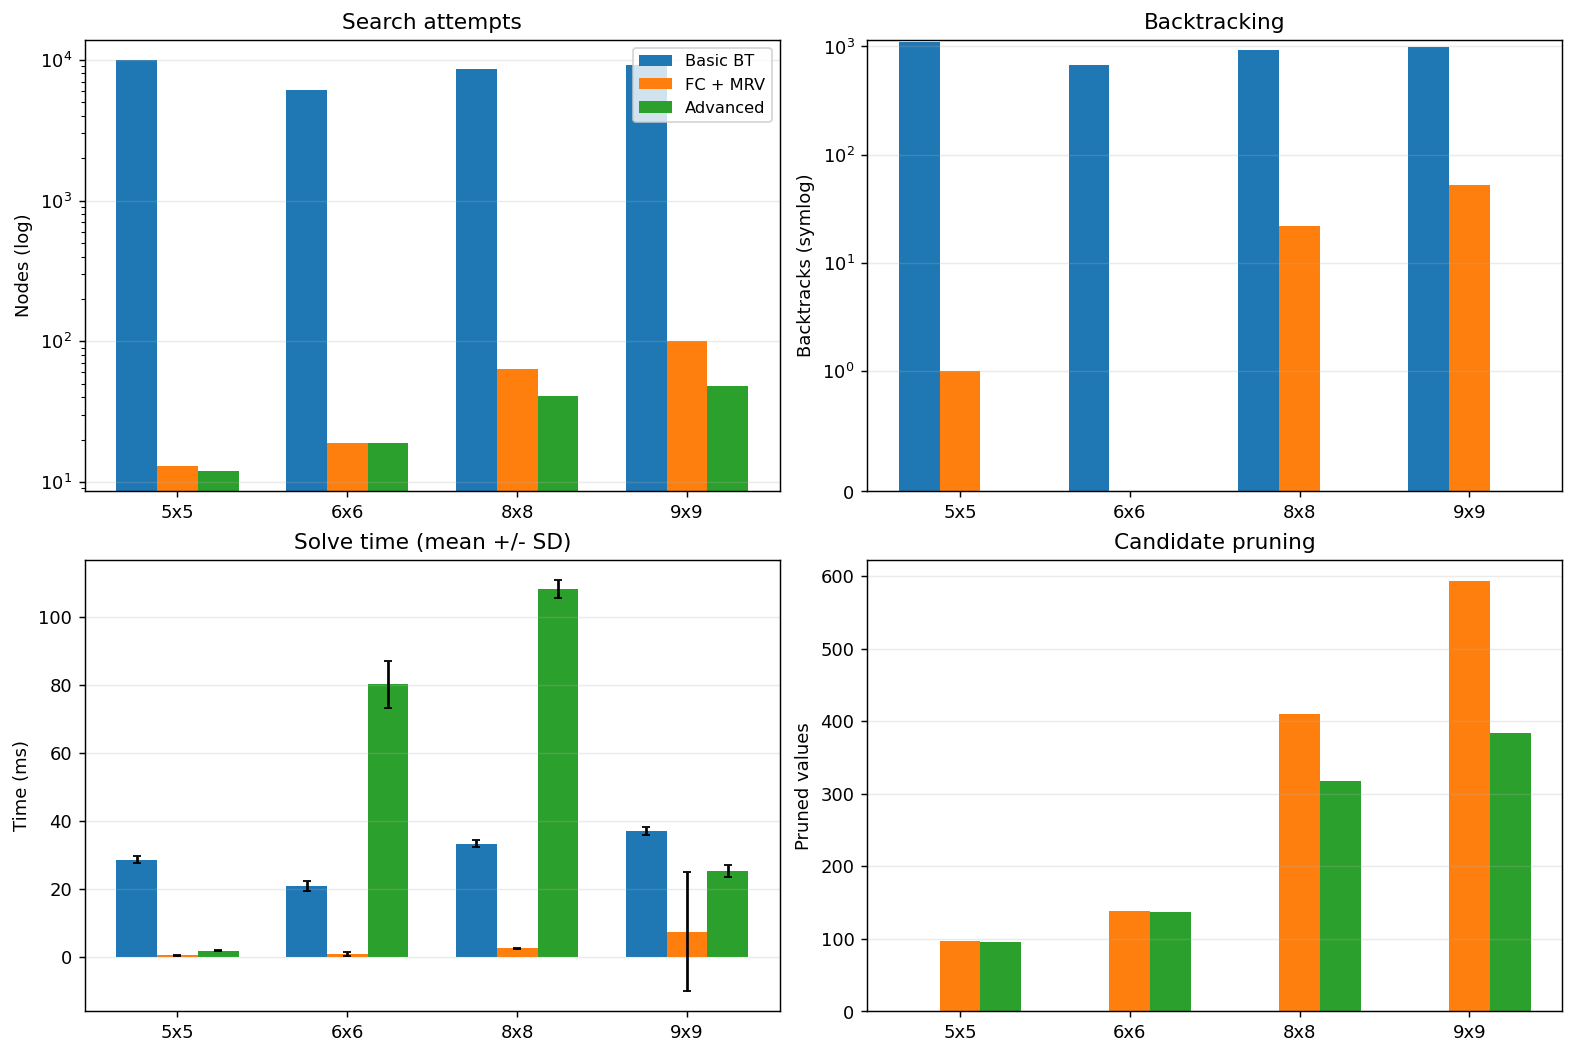

In [3]:
x = np.arange(len(boards))
width = 0.24
fig, axes = plt.subplots(2, 2, figsize=(12, 8), constrained_layout=True)
for i, label in enumerate(short_names.values()):
    sub = df_csp.xs(label, level='Mode').reindex(boards.keys())
    xx = x + (i-1)*width
    for ax, metric in zip(axes.flat, ['Nodes_mean','Backtracks_mean','Time_mean_ms','Pruned_mean']):
        kwargs = {'yerr': sub.Time_std_ms, 'capsize': 2} if metric == 'Time_mean_ms' else {}
        ax.bar(xx, sub[metric], width, label=label, **kwargs)
for ax, title, ylabel in zip(axes.flat, ['Search attempts','Backtracking','Solve time (mean +/- SD)','Candidate pruning'],
                            ['Nodes (log)','Backtracks (symlog)','Time (ms)','Pruned values']):
    ax.set_title(title); ax.set_ylabel(ylabel); ax.set_xticks(x, list(boards)); ax.grid(axis='y', alpha=.25)
axes[0,0].set_yscale('log')
axes[0,1].set_yscale('symlog', linthresh=1)  # preserves actual zero counts
axes[0,0].legend(fontsize=9)
fig.savefig(FIG_DIR / 'task3_csp_benchmark.png', dpi=200, bbox_inches='tight')
plt.show()

In [4]:
comparison = []
for board in boards:
    sub = df_csp.loc[board]
    base, adv = sub.loc['Basic BT'], sub.loc['Advanced']
    comparison.append({'Board':board, 'Nodes reduced (%)':100*(1-adv.Nodes_mean/base.Nodes_mean),
                       'Fastest mode':sub.Time_mean_ms.idxmin(),
                       'Advanced / Basic time':adv.Time_mean_ms/base.Time_mean_ms})
display(pd.DataFrame(comparison).round(3))

,Board,Nodes reduced (%),Fastest mode,Advanced / Basic time
0,5x5,99.879,FC + MRV,0.062
1,6x6,99.691,FC + MRV,3.872
2,8x8,99.526,FC + MRV,3.248
3,9x9,99.475,FC + MRV,0.680


**Nhận xét:** Đọc các kết quả thực tế ở bảng trên: giảm số nút hoặc quay lui không đồng nghĩa luôn giảm thời gian, do Extended AC-3 kiểm tra tổ hợp hỗ trợ và LCV mô phỏng lan truyền trên các bản sao. So sánh ba cấu hình theo nhóm kỹ thuật, không quy toàn bộ cải thiện cho riêng Forward Checking hay MRV. Các biểu đồ giữ giá trị quay lui bằng 0, không cộng hằng số giả.

## 2. Nghiệm Chi Tiết Đã Kiểm Chứng Của Bảng Kiểm Thử Phức Tạp 9x9 (Yêu Cầu 3.2)
In nghiệm do chế độ Advanced tìm được và kiểm tra từng dãy ngang/dọc.

In [5]:
csp_9x9 = boards['9x9']
assert solved_9x9 is not None and csp_9x9.verify_solution(solved_9x9)
for r, row in enumerate(csp_9x9.raw_grid):
    cells = []
    for col, spec in enumerate(row):
        if spec == 'B': cells.append(' ### ')
        elif isinstance(spec, dict): cells.append(f"{str(spec.get('down','')):>2}\\{str(spec.get('across','')):<2}")
        else: cells.append(f'  {solved_9x9[r,col]}  ')
    print(' | '.join(cells))
run_checks = []
for run in csp_9x9.runs:
    values = [solved_9x9[v.pos] for v in run.variables]
    run_checks.append({'Direction':run.orientation, 'Clue (row,col)':tuple(i+1 for i in run.clue_pos),
                       'Target':run.target_sum,'Digits':str(values), 'Actual':sum(values),
                       'AllDifferent':len(set(values))==len(values), 'Valid':run.is_satisfied_complete(solved_9x9)})
display(pd.DataFrame(run_checks))
assert all(r['Valid'] for r in run_checks)
print(f'Verified {len(run_checks)} / {len(run_checks)} runs.')

 ###  |  ###  | 44\   | 16\   |  9\   |  ###  | 15\   | 44\   |  ### 
 ###  |   \22 |   5   |   9   |   8   | 11\3  |   1   |   2   | 14\  
 ###  | 17\28 |   2   |   7   |   1   |   3   |   4   |   6   |   5  
  \14 |   8   |   6   |  ###  | 12\20 |   1   |   2   |   8   |   9  
  \17 |   9   |   8   | 29\22 |   3   |   2   |   8   |   9   |  7\  
 ###  | 12\28 |   9   |   8   |   6   |   5   |   \12 |   7   |   5  
  \14 |   3   |   4   |   5   |   2   |  7\   | 12\6  |   4   |   2  
  \39 |   9   |   3   |   7   |   1   |   6   |   8   |   5   |  ### 
 ###  |   \16 |   7   |   9   |   \8  |   1   |   4   |   3   |  ### 


,Direction,"Clue (row,col)",Target,Digits,Actual,AllDifferent,Valid
0,DOWN,"(1, 3)",44,"[5, 2, 6, 8, 9, 4, 3, 7]",44,True,True
1,DOWN,"(1, 4)",16,"[9, 7]",16,True,True
2,DOWN,"(1, 5)",9,"[8, 1]",9,True,True
3,DOWN,"(1, 7)",15,"[1, 4, 2, 8]",15,True,True
4,DOWN,"(1, 8)",44,"[2, 6, 8, 9, 7, 4, 5, 3]",44,True,True
5,ACROSS,"(2, 2)",22,"[5, 9, 8]",22,True,True
6,ACROSS,"(2, 6)",3,"[1, 2]",3,True,True
7,DOWN,"(2, 6)",11,"[3, 1, 2, 5]",11,True,True
8,DOWN,"(2, 9)",14,"[5, 9]",14,True,True
9,ACROSS,"(3, 2)",28,"[2, 7, 1, 3, 4, 6, 5]",28,True,True


Verified 28 / 28 runs.


## 3. Kiểm Thử Bảng Tùy Chỉnh & Trạng Thái Bộ Giải (Yêu Cầu 3.3)
Kiểm tra logic của BoardEditor và solver, không thay đổi các file JSON mẫu. Randomize dùng seed cố định để tái lập. Lưu/mở JSON dùng thư mục tạm. Đây là kiểm thử logic, không thay thế kiểm thử tương tác PyGame.

In [6]:
checks = []
def check(name, condition):
    checks.append({'Test':name,'Passed':bool(condition)})

for label, csp in boards.items():
    editor = BoardEditor(csp)
    editor.apply_bulk_rows(editor.bulk_rows())
    check(f'{label}: bulk round-trip', editor.grid == csp.raw_grid and editor.givens == csp.givens)
    editor.randomize_clues(random.Random(2026))
    randomized = editor.validate()
    res = KakuroSolver().solve(randomized)
    check(f'{label}: randomized clues', res.solved and randomized.verify_solution(res.assignment))

editor = BoardEditor.new(3)
editor.apply_bulk_rows(['# 0/4 0/6','3/0 1 0','7/0 0 4'])
custom = editor.validate()
for mode in modes:
    res = KakuroSolver(mode=mode, record_steps=True).solve(custom)
    check(f'Custom + givens: {short_names[mode]}', res.solved and custom.verify_solution(res.assignment)
          and res.assignment == {(1,1):1,(1,2):2,(2,1):3,(2,2):4}
          and res.steps_trace[-1].step_type == 'SOLVED')
with tempfile.TemporaryDirectory() as temp:
    path = Path(temp) / 'custom.json'
    editor.save(path)
    loaded = BoardEditor.load(path)
    check('Save/load JSON', loaded.grid == editor.grid and loaded.givens == editor.givens)
# Change both horizontal and vertical totals together; the new puzzle remains feasible.
editor.apply_bulk_rows(['# 0/6 0/4','3/0 2 0','7/0 0 3'])
changed = editor.validate()
res = KakuroSolver().solve(changed)
check('Bulk changes + solve again', res.solved and changed.verify_solution(res.assignment))
# Deliberately incompatible givens with structurally valid board.
editor.apply_bulk_rows(['# 0/4 0/6','3/0 9 0','7/0 0 4'])
conflict = editor.to_csp()
for mode in modes:
    res = KakuroSolver(mode=mode).solve(conflict)
    check(f'Inconsistent givens: {short_names[mode]}', res.status == 'UNSAT' and not res.solved)
limited = KakuroSolver(mode=SolverMode.PLAIN_BT, node_limit=1).solve(boards['5x5'])
check('Node limit is not UNSAT', limited.status == 'NODE_LIMIT')
cancel = Event(); cancel.set()
cancelled = KakuroSolver(cancel_event=cancel).solve(boards['5x5'])
check('Cancellation', cancelled.status == 'CANCELLED')
check('Solve after cancellation', KakuroSolver().solve(boards['5x5']).valid_verified)
trace = KakuroSolver(mode=SolverMode.PLAIN_BT, record_steps=True, max_recorded_steps=10).solve(boards['5x5'])
check('Trace cap preserves final result', trace.trace_truncated and len(trace.steps_trace) <= 10
      and trace.steps_trace[-1].step_type == 'SOLVED')
df_checks = pd.DataFrame(checks)
display(df_checks)
print(f'Passed: {df_checks.Passed.sum()}/{len(df_checks)}')
assert df_checks.Passed.all()

,Test,Passed
0,5x5: bulk round-trip,True
1,5x5: randomized clues,True
2,6x6: bulk round-trip,True
3,6x6: randomized clues,True
4,8x8: bulk round-trip,True
5,8x8: randomized clues,True
6,9x9: bulk round-trip,True
7,9x9: randomized clues,True
8,Custom + givens: Basic BT,True
9,Custom + givens: FC + MRV,True


Passed: 20/20


## 4. Kết Luận
Bảng số liệu và kết quả kiểm thử trên phản ánh đúng các module trong Task 3 tại thời điểm chạy Notebook. Tỷ lệ giải thành công chỉ áp dụng cho các trường hợp đã thử, không chứng minh mọi bảng tùy chỉnh đều có nghiệm hoặc nghiệm duy nhất. Kiểm thử GUI, thao tác Stop & Edit trong cửa sổ và tương thích macOS cần thực hiện riêng.